# Single cell ATAC without RNA

## Intro

Most single cell ATAC data has no RNA next to it: Cell Ranger ATAC runs, or
public fragment files. This vignette starts from a fragment file alone:
cells called from the fragment counts, QC and multiplets, peaks per cluster,
TF-IDF and LSI, clusters and differential accessibility, then gene activity
and labels transferred from an RNA reference.

The fragments are the ATAC half of the 10x PBMC 3k multiome used in the
[multiome vignette](atac_multiome.ipynb). That has a use here: its RNA half is
a reference built from the very same nuclei, so we can check the transferred
labels against the RNA clusters of each cell, which a real ATAC-only data
set cannot offer.

An ATAC-only experiment is a `SingleCellsAtac`: its own store holds the
peaks or tiles, and the ATAC functions take it exactly as they take the ATAC
side of a `SingleCellsMultiModal`. `modality="atac"` and the default both
name its store.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed

In [2]:
data_dir = bv.io.download_pbmc_multiome()
fragments = data_dir / "pbmc_unsorted_3k_atac_fragments.tsv.gz"
gtf = data_dir / "gencode.v32.primary_assembly.annotation.gtf.gz"
blacklist = data_dir / "hg38-blacklist.v2.bed.gz"
h5_path = data_dir / "pbmc_unsorted_3k_filtered_feature_bc_matrix.h5"

tempdir = tempfile.TemporaryDirectory()
base = Path(tempdir.name)

## Calling cells

Without a barcode list the cells come from the fragment counts: real cells
carry thousands of fragments, empty droplets a handful. The knee plot of
fragments per barcode, sorted, shows where the two meet. With Cell Ranger
ATAC output, `cellranger="singlecell.csv"` takes its calls instead.

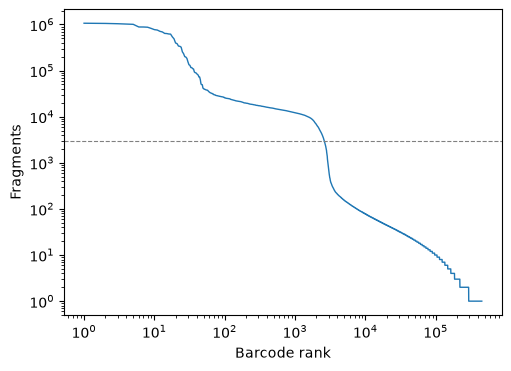

In [3]:
counts = bv.atac.barcode_fragment_counts(fragments)
rank = np.arange(1, counts.height + 1)
fig, ax = plt.subplots(figsize=(5, 3.6), layout="constrained")
ax.loglog(rank, counts["n_fragments"].to_numpy(), lw=1)
ax.axhline(3000, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Barcode rank")
ax.set_ylabel("Fragments")
plt.show()

The knee sits near 3,000 fragments. We call cells there and count them into
the peaks Cell Ranger called on all cells pooled, which every Cell Ranger ATAC
run ships. They are good enough to cluster on; better peaks come from the
clusters below.

In [4]:
first = bv.io.load_atac_fragments(
    base / "first",
    fragments,
    peaks=data_dir / "pbmc_unsorted_3k_atac_peaks.bed",
    min_fragments=3000,
)
first

  Counted 15_639_010 non-zeros over 81_156 genes in 7.97ms; converting in 1 phase(s).
  Phase 1/1: genes 0-81156, scatter 38.77ms, compress + write 99.20ms
  Conversion into gene-friendly format done: 146.63ms


SingleCellsAtac(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpx2gm983s/first',
  cells=2597 (kept 2597), features=81156,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
  atac=AtacInfo(kind='peak', count_mode='insertion', tf_idf=False, lsi=False, lsi_dropped=[]), gene_activity=False
)

## Quality control

The same metrics as with RNA next to it: fragments, nucleosome signal, TSS
enrichment, and AMULET's multiplet calls, which need nothing but the
fragments.

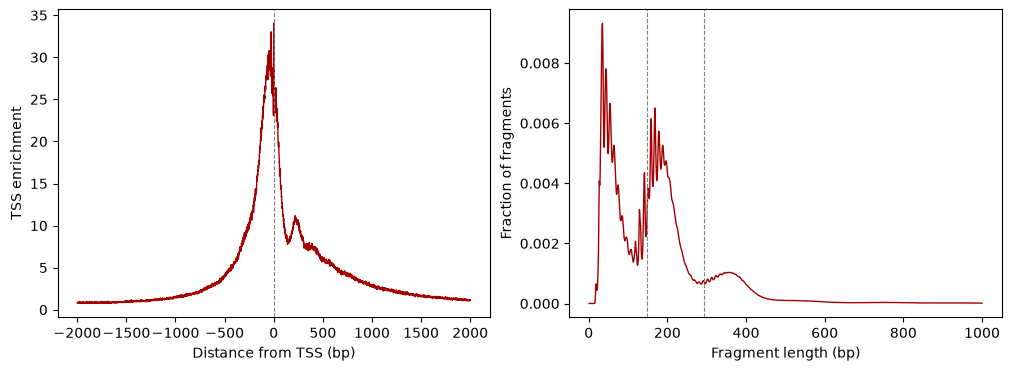

In [5]:
qc = bv.atac.fragment_qc(first, fragments, gtf)
amulet = bv.atac.amulet(first, fragments, restrict_beds=[blacklist])
tss_profile, frag_lengths = bv.atac.fragment_profiles(first, fragments, gtf)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
bv.pl.tss_profile_plot(tss_profile, ax=axes[0])
bv.pl.fragment_length_plot(frag_lengths, ax=axes[1])
plt.show()

In [6]:
obs = first.obs(
    cols=[
        "cell_idx",
        "atac_n_fragments",
        "atac_nucleosome_signal",
        "atac_tss_enrichment",
        "amulet_multiplet",
    ]
)
keep = (
    (obs["atac_nucleosome_signal"] < 2)
    & (obs["atac_tss_enrichment"] > 2)
    & ~obs["amulet_multiplet"]
)
print(f"keeping {keep.sum()} of {obs.height} cells")
first.set_cells_to_keep(obs.filter(keep)["cell_idx"].to_numpy())

keeping 2460 of 2597 cells


## First clusters

TF-IDF, LSI and Leiden on Cell Ranger's peaks give the clusters to call
peaks on.

In [7]:
bv.atac.run_tfidf(first)
bv.atac.find_top_features(first, min_cutoff="q25")
bv.atac.calculate_lsi(first, n_comp=30)
bv.graph.find_neighbours(first, embd_to_use="lsi")
bv.graph.find_clusters(first, res=0.8)

Sparse PCA: finished the data preparations in 33.26ms


Sparse PCA: finished calculations in 1.48s
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 10.93ms
Generated KmKnn index: 11.07ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 5.42ms
Queried KmKnn index: 5.44ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 5.93ms


## Peaks

Peaks per cluster, merged, blacklist and contigs dropped, then the fragments
counted against them into the experiment we keep, for the cells that passed
QC.

In [8]:
peaks = bv.atac.call_peaks(first, fragments, group_by="leiden_clustering")
peaks = peaks.filter(pl.col("chrom").str.contains(r"^chr[0-9XY]+$"))
peaks = bv.atac.remove_blacklisted(peaks, blacklist)
x = bv.io.load_atac_fragments(
    base / "peaks",
    fragments,
    peaks=peaks,
    barcodes=first.cell_ids(filtered=True),
)
bv.atac.fragment_qc(x, fragments, gtf)
bv.atac.annotate_peaks(x, gtf)
x

  Counted 14_172_248 non-zeros over 117_829 genes in 16.04ms; converting in 1 phase(s).
  Phase 1/1: genes 0-117829, scatter 34.48ms, compress + write 121.43ms
  Conversion into gene-friendly format done: 172.88ms


SingleCellsAtac(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpx2gm983s/peaks',
  cells=2460 (kept 2460), features=117829,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
  atac=AtacInfo(kind='peak', count_mode='insertion', tf_idf=False, lsi=False, lsi_dropped=[]), gene_activity=False
)

## TF-IDF, LSI, clusters

Sparse PCA: finished the data preparations in 52.33ms


Sparse PCA: finished calculations in 1.86s


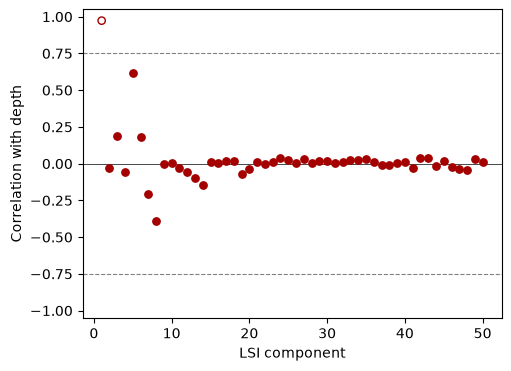

In [9]:
bv.atac.run_tfidf(x)
bv.atac.find_top_features(x, min_cutoff="q25")
bv.atac.calculate_lsi(x, n_comp=50)
bv.pl.lsi_depth_plot(bv.atac.get_lsi_depth_cor(x))
plt.show()

Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 11.55ms
Generated KmKnn index: 11.68ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 13.74ms
Queried KmKnn index: 13.76ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 5.04ms


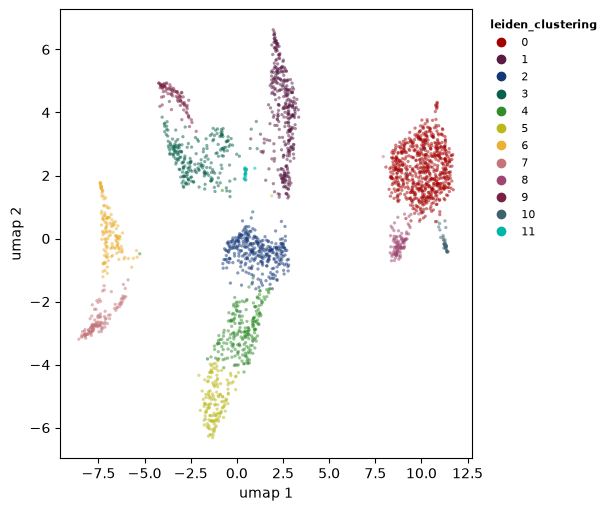

In [10]:
bv.graph.find_neighbours(x, embd_to_use="lsi", no_embd_to_use=30)
bv.graph.find_clusters(x, res=0.8)
bv.embed.umap(x, embd_to_use="lsi")
bv.pl.embedding_plot(x, "umap", "leiden_clustering", discrete=True, point_size=0.5)
plt.show()

## Differential accessibility

On an ATAC experiment the marker functions test peaks by default, with the
logistic regression that takes the library size as covariate. As in the
multiome vignette, treat the p-values as a ranking.

In [11]:
da = bv.de.find_all_markers(x, "leiden_clustering", verbose=0)
annotation = x.var(modality="atac", cols=["feature_id", "closest_gene"])
da = da.join(annotation, on="feature_id", how="left")
da.filter(pl.col("fdr") < 0.05).sort("lfc", descending=True).head(10)

grp,feature_id,lfc,prop1,prop2,z_scores,p_values,fdr,closest_gene
i32,str,f64,f64,f64,f64,f64,f64,str
11,"""chr7:98642109-98642369""",2.572098,0.52381,0.00041,9.989734,8.4518e-24,3.0360e-19,"""NPTX2"""
11,"""chr10:33715301-33715777""",2.246233,0.47619,0.00123,9.140167,3.1178e-20,5.5997e-16,"""NRP1"""
11,"""chr7:98641559-98642020""",2.126829,0.47619,0.00287,8.65297,2.5088e-18,2.2530e-14,"""NPTX2"""
11,"""chr3:53190375-53190965""",2.04224,0.47619,0.00656,8.244228,8.3115e-17,3.7320e-13,"""PRKCD"""
11,"""chr14:89773085-89773520""",2.030936,0.428571,0.00287,8.253377,7.6990e-17,3.7320e-13,"""EFCAB11"""
11,"""chr3:134956410-134956769""",1.952577,0.380952,0.00082,8.299813,5.2138e-17,3.1214e-13,"""EPHB1"""
11,"""chr2:176491200-176491557""",1.939827,0.428571,0.00287,8.010924,5.6925e-16,1.5729e-12,"""MTX2"""
11,"""chr20:38725341-38725627""",1.895438,0.380952,0.00328,7.818633,2.6700e-15,5.3283e-12,"""SLC32A1"""
11,"""chr9:106757643-106757934""",1.892387,0.380952,0.0,8.895523,2.9072e-19,3.4810e-15,"""ZNF462"""


## Labels from an RNA reference

Gene activity puts the ATAC cells in gene space, where an RNA reference can
meet them. The reference here is the RNA of the same 3k nuclei, clustered
the usual way; in practice it would be any annotated RNA data set of the
tissue.

In [12]:
rna = bv.io.load_tenx_h5(base / "rna", h5_path)
bv.pp.find_hvg(rna, hvg_no=2000)
bv.pp.calculate_pca(rna, no_pcs=30)
bv.graph.find_neighbours(rna)
bv.graph.find_clusters(rna, res=0.8, name="rna_cluster")

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading 10x matrix structure (shape: 3_009 cells x 117_757 features)...
  Features after type filtering: 36_601 / 117_757
Quality pass - gene and cell statistics:
  Processed 100% of chunks (1/1)
  Genes passing filter: 16_556 / 36_601
Quality pass done: 122.55ms
  Cells passing filter: 2_956 / 3_009
Step 2/3: QC Results:
  Genes passing QC: 16_556 / 117_757
  Cells passing QC: 2_956 / 3_009
Step 3/3: Writing cells to CSR format...
  Processing 2_956 cells in batches of 8_192...
  Processed 2_956 / 2_956 cells
Converting the cell-based data into the gene-based format.
  Writing complete in 59.58ms


  Counted 4_723_733 non-zeros over 16_556 genes in 3.83ms; converting in 1 phase(s).


  Phase 1/1: genes 0-16556, scatter 10.37ms, compress + write 23.09ms
  Conversion into gene-friendly format done: 38.86ms
HVG (VST): 16_556 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 14.66ms
HVG (VST): Fitted Loess in 791.08µs
HVG (VST): Standardised variance in 504.04µs (115 gene(s) re-read for the clip)
HVG (VST): Total run time -> 16.00ms


Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 18.13ms
Sparse PCA: finished the data preparations in 1.11ms
Sparse PCA: finished calculations in 141.82ms
Sparse PCA: total run time -> 161.13ms
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 14.38ms
Generated KmKnn index: 14.53ms
Querying kMkNN index (self) ...
... queried kMkNN index (self) in 14.79ms
Queried KmKnn index: 14.80ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 5.38ms


In [13]:
ga = bv.atac.gene_activity(x, fragments, gtf)
transfer = bv.annotate.transfer_labels_seurat(
    rna, ga, "rna_cluster", x.atac_cache.embeddings["lsi"], weight_owner=x
)

  Counted 14_312_142 non-zeros over 19_675 genes in 17.83ms; converting in 1 phase(s).
  Phase 1/1: genes 0-19675, scatter 42.34ms, compress + write 20.41ms
  Conversion into gene-friendly format done: 81.85ms


Each ATAC cell's predicted cluster against the RNA cluster of the same
barcode:

In [14]:
truth = rna.obs(cols=["cell_id", "rna_cluster"])
pred = pl.DataFrame(
    {
        "cell_id": x.cell_ids(filtered=True),
        "predicted": transfer["predicted_rna_cluster"].cast(pl.String),
    }
).join(truth, on="cell_id", how="inner")
agree = (pred["predicted"] == pred["rna_cluster"].cast(pl.String)).mean()
print(f"{pred.height} shared cells; the transferred label is right for {agree:.1%}")

2399 shared cells; the transferred label is right for 87.5%


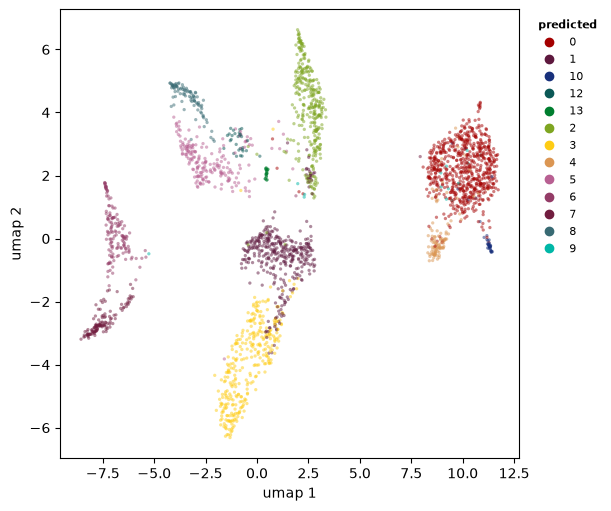

In [15]:
x.add_obs(
    pl.DataFrame(
        {
            "predicted": transfer["predicted_rna_cluster"].cast(pl.String),
        }
    )
)
bv.pl.embedding_plot(x, "umap", "predicted", discrete=True, point_size=0.5)
plt.show()